In [1]:
import sys
import shutil
import subprocess
from pathlib import Path
from importlib.metadata import version, PackageNotFoundError

print("PYTHON:", sys.version.split()[0])
print("CARPETA ACTUAL:", Path.cwd())

print("\nLIBRERÍAS INSTALADAS")
paquetes = [
    "torch",
    "torchvision",
    "ultralytics",
    "opencv-python",
    "opencv-python-headless",
    "numpy",
    "pandas",
    "matplotlib",
]

for paquete in paquetes:
    try:
        print(f"{paquete}: {version(paquete)}")
    except PackageNotFoundError:
        print(f"{paquete}: no detectado")

print("\nFFMPEG:", shutil.which("ffmpeg") or "no detectado")

print("\nGPU")
if shutil.which("nvidia-smi"):
    resultado = subprocess.run(
        [
            "nvidia-smi",
            "--query-gpu=name,memory.total,memory.used,driver_version",
            "--format=csv",
        ],
        capture_output=True,
        text=True,
        timeout=20,
    )
    print(resultado.stdout or resultado.stderr)
else:
    print("No se encuentra nvidia-smi.")

print("\nCARPETAS DE REFERENCIA")
for ruta in [
    Path("/workspace/equipo5"),
    Path("/workspace/ai-training-examples"),
]:
    print(f"{ruta}: {'existe' if ruta.exists() else 'no encontrada'}")

PYTHON: 3.13.12
CARPETA ACTUAL: /workspace/equipo5/PAULA

LIBRERÍAS INSTALADAS
torch: 2.12.1+cu126
torchvision: 0.27.1+cu126
ultralytics: no detectado
opencv-python: 4.13.0.92
opencv-python-headless: no detectado
numpy: 2.5.2
pandas: 3.0.3
matplotlib: 3.11.0

FFMPEG: /usr/bin/ffmpeg

GPU
name, memory.total [MiB], memory.used [MiB], driver_version
Tesla V100S-PCIE-32GB, 32768 MiB, 0 MiB, 580.178.04
Tesla V100S-PCIE-32GB, 32768 MiB, 0 MiB, 580.178.04


CARPETAS DE REFERENCIA
/workspace/equipo5: existe
/workspace/ai-training-examples: existe


In [1]:
import sys
import shutil
import subprocess
from pathlib import Path
from importlib.metadata import version, PackageNotFoundError

print("PYTHON:", sys.version.split()[0])
print("CARPETA ACTUAL:", Path.cwd())

print("\nLIBRERÍAS INSTALADAS")
paquetes = [
    "torch",
    "torchvision",
    "ultralytics",
    "opencv-python",
    "opencv-python-headless",
    "numpy",
    "pandas",
    "matplotlib",
]

for paquete in paquetes:
    try:
        print(f"{paquete}: {version(paquete)}")
    except PackageNotFoundError:
        print(f"{paquete}: no detectado")

print("\nFFMPEG:", shutil.which("ffmpeg") or "no detectado")

print("\nGPU")
if shutil.which("nvidia-smi"):
    resultado = subprocess.run(
        [
            "nvidia-smi",
            "--query-gpu=name,memory.total,memory.used,driver_version",
            "--format=csv",
        ],
        capture_output=True,
        text=True,
        timeout=20,
    )
    print(resultado.stdout or resultado.stderr)
else:
    print("No se encuentra nvidia-smi.")

print("\nCARPETAS DE REFERENCIA")
for ruta in [
    Path("/workspace/equipo5"),
    Path("/workspace/ai-training-examples"),
]:
    print(f"{ruta}: {'existe' if ruta.exists() else 'no encontrada'}")

PYTHON: 3.13.12
CARPETA ACTUAL: /workspace/equipo5/PAULA

LIBRERÍAS INSTALADAS
torch: 2.12.1+cu126
torchvision: 0.27.1+cu126
ultralytics: no detectado
opencv-python: 4.13.0.92
opencv-python-headless: no detectado
numpy: 2.5.2
pandas: 3.0.3
matplotlib: 3.11.0

FFMPEG: /usr/bin/ffmpeg

GPU
name, memory.total [MiB], memory.used [MiB], driver_version
Tesla V100S-PCIE-32GB, 32768 MiB, 0 MiB, 580.178.04
Tesla V100S-PCIE-32GB, 32768 MiB, 0 MiB, 580.178.04


CARPETAS DE REFERENCIA
/workspace/equipo5: existe
/workspace/ai-training-examples: existe


In [3]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA disponible:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU utilizada:", torch.cuda.get_device_name(0))

    try:
        with torch.inference_mode():
            x = torch.ones((256, 256), device="cuda:0")
            resultado = (x @ x).mean().item()

        print("Resultado:", resultado)
        print("✅ Prueba de cálculo en GPU completada.")

        del x
        torch.cuda.empty_cache()

    except Exception as error:
        print("❌ La prueba de GPU ha fallado:")
        print(type(error).__name__, str(error))
else:
    print("PyTorch no puede acceder a la GPU.")

PyTorch: 2.12.1+cu126
CUDA disponible: True
GPU utilizada: Tesla V100S-PCIE-32GB
Resultado: 256.0
✅ Prueba de cálculo en GPU completada.


Archivo: prueba_01.mp4
Resolución: 1280 × 720 píxeles
Fotogramas por segundo (FPS): 30.00
Fotogramas declarados: 7871
Duración aproximada: 262.37 segundos


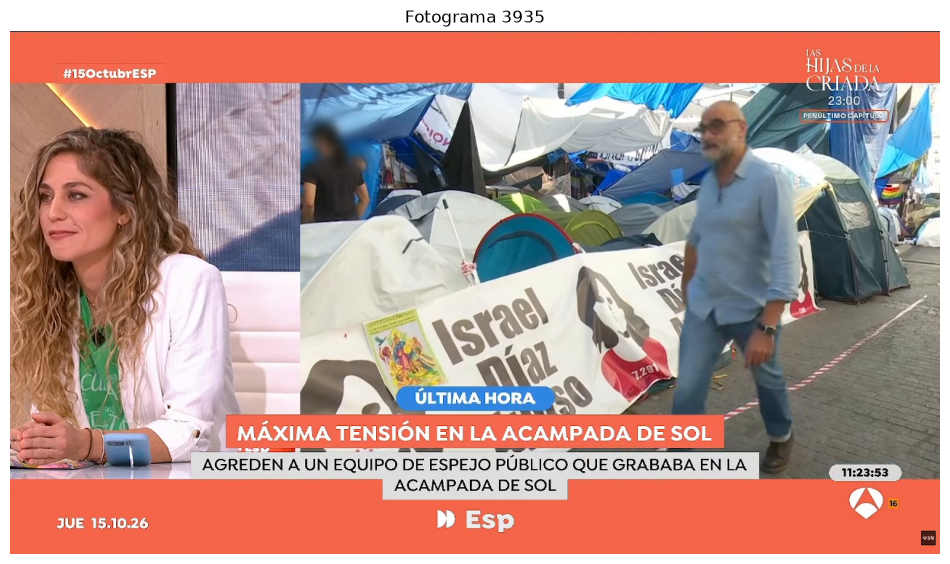

In [7]:
from pathlib import Path
import cv2
import matplotlib.pyplot as plt

video_path = Path("/workspace/equipo5/PAULA/prueba_01.mp4")

if not video_path.is_file():
    print(f"No se encuentra el vídeo: {video_path}")
    print("Súbelo a esa carpeta o modifica el nombre en video_path.")
else:
    cap = cv2.VideoCapture(str(video_path))

    try:
        if not cap.isOpened():
            raise RuntimeError("OpenCV no ha podido abrir el vídeo.")

        fps = cap.get(cv2.CAP_PROP_FPS)
        total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
        height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

        print("Archivo:", video_path.name)
        print(f"Resolución: {width} × {height} píxeles")
        print(f"Fotogramas por segundo (FPS): {fps:.2f}")
        print("Fotogramas declarados:", total_frames)

        if fps > 0 and total_frames > 0:
            print(f"Duración aproximada: {total_frames / fps:.2f} segundos")

        frame_index = max(0, total_frames // 2)
        cap.set(cv2.CAP_PROP_POS_FRAMES, frame_index)
        ok, frame = cap.read()

        if not ok:
            raise RuntimeError("No se ha podido leer el fotograma.")

        frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

        plt.figure(figsize=(12, 7))
        plt.imshow(frame_rgb)
        plt.title(f"Fotograma {frame_index}")
        plt.axis("off")
        plt.show()

    finally:
        cap.release()

Downloading: "https://download.pytorch.org/models/fasterrcnn_mobilenet_v3_large_320_fpn-907ea3f9.pth" to /workspace/equipo5/PAULA/modelos_cache/checkpoints/fasterrcnn_mobilenet_v3_large_320_fpn-907ea3f9.pth


100%|██████████| 74.2M/74.2M [00:00<00:00, 223MB/s]


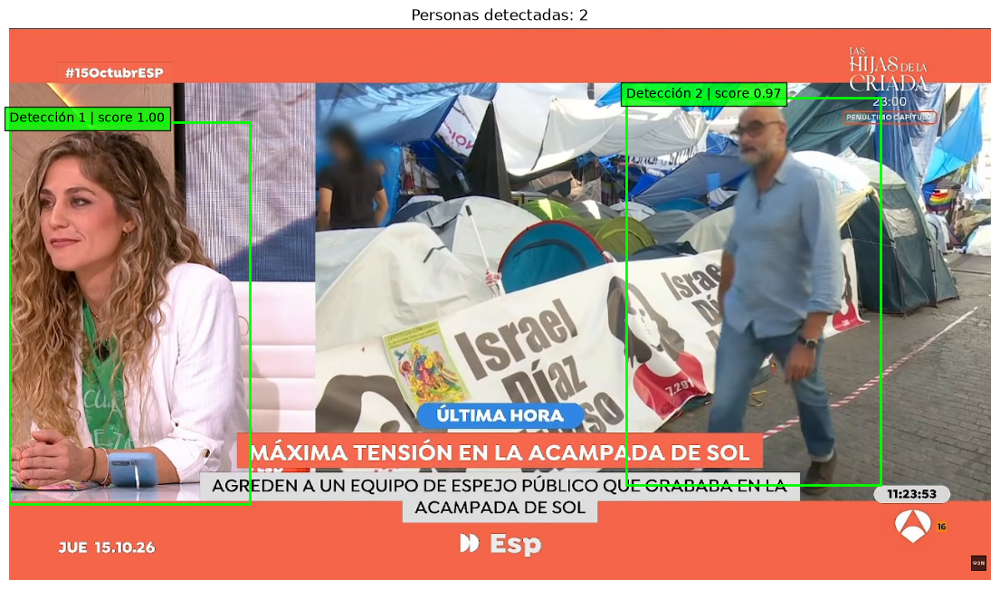

,deteccion,score_modelo,ocupacion_rectangulo_pct
0,1,0.998,16.93
1,2,0.970,18.14


In [8]:
from pathlib import Path
import torch
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from torchvision.models.detection import (
    fasterrcnn_mobilenet_v3_large_320_fpn,
    FasterRCNN_MobileNet_V3_Large_320_FPN_Weights,
)

# Guardar la descarga dentro de tu carpeta de trabajo
cache_modelos = Path("/workspace/equipo5/PAULA/modelos_cache")
cache_modelos.mkdir(parents=True, exist_ok=True)
torch.hub.set_dir(str(cache_modelos))

# Cargar un detector preentrenado
pesos = FasterRCNN_MobileNet_V3_Large_320_FPN_Weights.COCO_V1
dispositivo = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

modelo_visual = fasterrcnn_mobilenet_v3_large_320_fpn(
    weights=pesos
).to(dispositivo).eval()

# Utilizar el fotograma leído en la celda anterior
imagen_tensor = (
    torch.from_numpy(frame_rgb.copy())
    .permute(2, 0, 1)
    .float()
    / 255.0
)

with torch.inference_mode():
    prediccion = modelo_visual(
        [imagen_tensor.to(dispositivo)]
    )[0]

# Conservar únicamente detecciones de personas
umbral = 0.70  # Valor inicial para probar; después lo evaluaremos
clase_persona = pesos.meta["categories"].index("person")

seleccion = (
    (prediccion["labels"] == clase_persona)
    & (prediccion["scores"] >= umbral)
)

cajas = prediccion["boxes"][seleccion].cpu().numpy()
scores = prediccion["scores"][seleccion].cpu().numpy()

alto, ancho = frame_rgb.shape[:2]
filas = []

fig, ax = plt.subplots(figsize=(14, 8))
ax.imshow(frame_rgb)

for numero, (caja, score) in enumerate(zip(cajas, scores), start=1):
    x1, y1, x2, y2 = caja
    ocupacion = 100 * ((x2 - x1) * (y2 - y1)) / (ancho * alto)

    ax.add_patch(Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        fill=False,
        edgecolor="lime",
        linewidth=2,
    ))

    ax.text(
        x1, max(12, y1),
        f"Detección {numero} | score {score:.2f}",
        color="black",
        bbox=dict(facecolor="lime", alpha=0.8),
    )

    filas.append({
        "deteccion": numero,
        "score_modelo": round(float(score), 3),
        "ocupacion_rectangulo_pct": round(float(ocupacion), 2),
    })

ax.set_title(f"Personas detectadas: {len(filas)}")
ax.axis("off")
plt.show()

tabla_detecciones = pd.DataFrame(
    filas,
    columns=["deteccion", "score_modelo", "ocupacion_rectangulo_pct"],
)
display(tabla_detecciones)

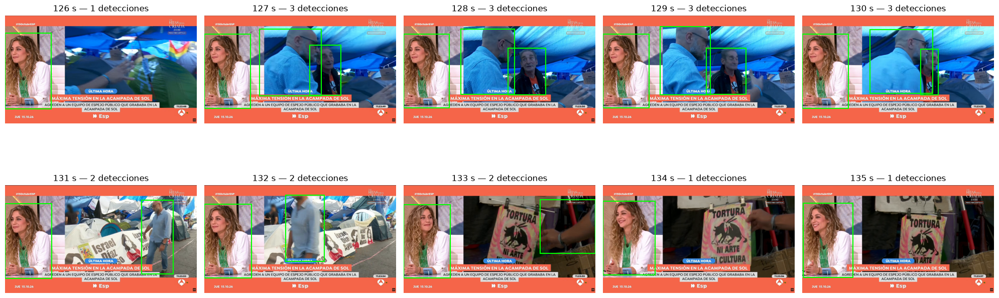

,segundo_solicitado,personas_detectadas,estado
0,126,1,procesado
1,127,3,procesado
2,128,3,procesado
3,129,3,procesado
4,130,3,procesado
5,131,2,procesado
6,132,2,procesado
7,133,2,procesado
8,134,1,procesado
9,135,1,procesado


Tabla guardada en: /workspace/equipo5/PAULA/resultados/conteo_muestra_126_135s.csv


In [10]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from pathlib import Path

# Fragmento cercano al fotograma que acabamos de analizar
inicio_s = 126
fin_s = 136  # No incluido: analizaremos del segundo 126 al 135

cap = cv2.VideoCapture(
    "/workspace/equipo5/PAULA/prueba_01.mp4"
)

resumen = []
fig, ejes = plt.subplots(2, 5, figsize=(20, 8))

try:
    if not cap.isOpened():
        raise RuntimeError("No se ha podido abrir el vídeo.")

    for segundo, ax in zip(range(inicio_s, fin_s), ejes.flat):
        cap.set(cv2.CAP_PROP_POS_MSEC, segundo * 1000)
        ok, imagen = cap.read()

        if not ok:
            ax.set_title(f"{segundo} s — lectura fallida")
            ax.axis("off")
            resumen.append({
                "segundo_solicitado": segundo,
                "personas_detectadas": None,
                "estado": "lectura_fallida",
            })
            continue

        rgb = cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB)
        tensor = (
            torch.from_numpy(rgb.copy())
            .permute(2, 0, 1)
            .float() / 255.0
        )

        with torch.inference_mode():
            salida = modelo_visual(
                [tensor.to(dispositivo)]
            )[0]

        conservar = (
            (salida["labels"] == clase_persona)
            & (salida["scores"] >= umbral)
        )
        cajas = salida["boxes"][conservar].cpu().numpy()

        ax.imshow(rgb)
        for x1, y1, x2, y2 in cajas:
            ax.add_patch(Rectangle(
                (x1, y1), x2 - x1, y2 - y1,
                fill=False, edgecolor="lime", linewidth=1.5
            ))

        ax.set_title(f"{segundo} s — {len(cajas)} detecciones")
        ax.axis("off")

        resumen.append({
            "segundo_solicitado": segundo,
            "personas_detectadas": len(cajas),
            "estado": "procesado",
        })

finally:
    cap.release()

plt.tight_layout()
plt.show()

tabla_muestra = pd.DataFrame(resumen)
display(tabla_muestra)

carpeta_resultados = Path("/workspace/equipo5/PAULA/resultados")
carpeta_resultados.mkdir(exist_ok=True)

ruta_csv = carpeta_resultados / "conteo_muestra_126_135s.csv"
tabla_muestra.to_csv(ruta_csv, index=False)

print("Tabla guardada en:", ruta_csv)

In [11]:
from pathlib import Path
import cv2
import torch
import pandas as pd
import math

video_path = Path("/workspace/equipo5/PAULA/prueba_01.mp4")
salida_dir = Path("/workspace/equipo5/PAULA/resultados")
salida_dir.mkdir(exist_ok=True)

inicio_s = 126.0
fin_s = 128.0  # No incluido
umbral = 0.70

registros_frames = []
registros_personas = []

cap = cv2.VideoCapture(str(video_path))

try:
    if not cap.isOpened():
        raise RuntimeError("No se ha podido abrir el vídeo.")

    fps = cap.get(cv2.CAP_PROP_FPS)
    if fps <= 0:
        raise RuntimeError("No se ha podido obtener la frecuencia de vídeo.")

    # Límites nominales para seleccionar esta muestra.
    primer_frame = round(inicio_s * fps)
    ultimo_frame = round(fin_s * fps)

    # Leer desde el inicio para mantener el índice de fotograma.
    for frame_index in range(ultimo_frame):
        if frame_index < primer_frame:
            if not cap.grab():
                raise RuntimeError(
                    f"Lectura interrumpida antes del fotograma {frame_index}."
                )
            continue

        ok, frame = cap.read()
        if not ok:
            raise RuntimeError(
                f"No se ha podido leer el fotograma {frame_index}."
            )

        tiempo_ms = cap.get(cv2.CAP_PROP_POS_MSEC)
        tiempo_valido = math.isfinite(tiempo_ms) and tiempo_ms > 0
        timestamp_s = tiempo_ms / 1000 if tiempo_valido else None

        alto, ancho = frame.shape[:2]
        rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        tensor = (
            torch.from_numpy(rgb.copy())
            .permute(2, 0, 1)
            .float() / 255.0
        )

        with torch.inference_mode():
            pred = modelo_visual([tensor.to(dispositivo)])[0]

        conservar = (
            (pred["labels"] == clase_persona)
            & (pred["scores"] >= umbral)
        )

        cajas = pred["boxes"][conservar].cpu().numpy()
        scores = pred["scores"][conservar].cpu().numpy()

        # Una fila por fotograma, incluso si no hay detecciones.
        registros_frames.append({
            "video_id": video_path.stem,
            "frame_index": frame_index,
            "timestamp_s": timestamp_s,
            "timestamp_source": (
                "opencv_pos_msec" if tiempo_valido else "no_disponible"
            ),
            "tiempo_nominal_s": frame_index / fps,
            "ancho_px": ancho,
            "alto_px": alto,
            "personas_detectadas": len(cajas),
            "estado": "procesado",
        })

        # Una fila por persona detectada en ese fotograma.
        for numero, (caja, score) in enumerate(zip(cajas, scores), start=1):
            x1, y1, x2, y2 = map(float, caja)

            # Limitar el rectángulo al encuadre.
            x1, x2 = max(0, x1), min(ancho, x2)
            y1, y2 = max(0, y1), min(alto, y2)

            area_pct = (
                100 * max(0, x2 - x1) * max(0, y2 - y1)
                / (ancho * alto)
            )

            registros_personas.append({
                "video_id": video_path.stem,
                "frame_index": frame_index,
                "timestamp_s": timestamp_s,
                "detection_id": f"f{frame_index}_d{numero}",
                "x1": x1,
                "y1": y1,
                "x2": x2,
                "y2": y2,
                "bbox_area_pct": area_pct,
                "detection_score": float(score),
                "review_status": "pendiente",
            })

        if len(registros_frames) % 15 == 0:
            print(f"Procesados {len(registros_frames)} fotogramas...")

finally:
    cap.release()

tabla_frames = pd.DataFrame(registros_frames)

columnas_personas = [
    "video_id", "frame_index", "timestamp_s", "detection_id",
    "x1", "y1", "x2", "y2", "bbox_area_pct",
    "detection_score", "review_status",
]
tabla_personas = pd.DataFrame(
    registros_personas, columns=columnas_personas
)

# Comprobar las marcas temporales antes de usarlas para sincronizar.
tiempos = tabla_frames["timestamp_s"]
tiempos_correctos = (
    tiempos.notna().all()
    and tiempos.diff().dropna().gt(0).all()
)

tabla_frames.to_csv(
    salida_dir / "fotogramas_126_128s.csv", index=False
)
tabla_personas.to_csv(
    salida_dir / "personas_126_128s.csv", index=False
)

print("\nFotogramas procesados:", len(tabla_frames))
print("Detecciones acumuladas:", len(tabla_personas))
print(
    "Tiempos disponibles y crecientes:",
    "SÍ" if tiempos_correctos else "NO: revisar antes de sincronizar"
)
print("Archivos guardados en:", salida_dir)

display(tabla_frames.head())
display(tabla_personas.head())

Procesados 15 fotogramas...
Procesados 30 fotogramas...
Procesados 45 fotogramas...
Procesados 60 fotogramas...

Fotogramas procesados: 60
Detecciones acumuladas: 160
Tiempos disponibles y crecientes: SÍ
Archivos guardados en: /workspace/equipo5/PAULA/resultados


,video_id,frame_index,timestamp_s,timestamp_source,tiempo_nominal_s,ancho_px,alto_px,personas_detectadas,estado
0,prueba_01,3780,126.000000,opencv_pos_msec,126.000000,1280,720,1,procesado
1,prueba_01,3781,126.033333,opencv_pos_msec,126.033333,1280,720,1,procesado
2,prueba_01,3782,126.066667,opencv_pos_msec,126.066667,1280,720,1,procesado
3,prueba_01,3783,126.100000,opencv_pos_msec,126.100000,1280,720,1,procesado
4,prueba_01,3784,126.133333,opencv_pos_msec,126.133333,1280,720,1,procesado


,video_id,frame_index,timestamp_s,detection_id,x1,y1,x2,y2,bbox_area_pct,detection_score,review_status
0,prueba_01,3780,126.000000,f3780_d1,0.858051,118.266342,308.977020,621.801453,16.834713,0.998706,pendiente
1,prueba_01,3781,126.033333,f3781_d1,1.237535,118.770294,309.686279,619.918335,16.772839,0.998855,pendiente
2,prueba_01,3782,126.066667,f3782_d1,1.176431,118.744232,309.437103,619.843140,16.760969,0.998872,pendiente
3,prueba_01,3783,126.100000,f3783_d1,1.539926,118.536972,308.685852,619.555176,16.697667,0.998639,pendiente
4,prueba_01,3784,126.133333,f3784_d1,0.000000,117.868866,303.019318,632.945496,16.935565,0.998643,pendiente


In [16]:
from pathlib import Path
import subprocess
import sys

entorno_ocr = Path("/workspace/equipo5/PAULA/entorno_ocr")
python_ocr = entorno_ocr / "bin" / "python"

# Crear un entorno propio que pueda utilizar las librerías existentes.
if not python_ocr.exists():
    subprocess.run(
        [
            sys.executable, "-m", "venv",
            "--system-site-packages",
            str(entorno_ocr),
        ],
        check=True,
    )

# Las nuevas instalaciones quedan en este entorno, no en el compartido.
instalacion = subprocess.run(
    [
        str(python_ocr), "-m", "pip", "install",
        "--disable-pip-version-check",
        "easyocr==1.7.2",
    ],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
)

print(instalacion.stdout[-10000:])

if instalacion.returncode != 0:
    print("\n❌ La instalación no se ha completado. Comparte el error.")
else:
    comprobacion = subprocess.run(
        [
            str(python_ocr), "-c",
            "import easyocr, torch; "
            "print('EasyOCR:', easyocr.__version__); "
            "print('PyTorch:', torch.__version__); "
            "print('CUDA disponible:', torch.cuda.is_available())"
        ],
        capture_output=True,
        text=True,
    )

    print("\nCOMPROBACIÓN")
    print(comprobacion.stdout)
    print(comprobacion.stderr)

    if comprobacion.returncode == 0:
        print("✅ Entorno OCR preparado.")
    else:
        print("❌ Hay un problema de compatibilidad; revisaremos el error.")



COMPROBACIÓN
EasyOCR: 1.7.2
PyTorch: 2.12.1+cu126
CUDA disponible: True


✅ Entorno OCR preparado.



Progress: |--------------------------------------------------| 0.0% Complete
Progress: |--------------------------------------------------| 0.0% Complete
Progress: |--------------------------------------------------| 0.0% Complete
Progress: |--------------------------------------------------| 0.0% Complete
Progress: |--------------------------------------------------| 0.0% Complete
Progress: |--------------------------------------------------| 0.1% Complete
Progress: |--------------------------------------------------| 0.1% Complete
Progress: |--------------------------------------------------| 0.1% Complete
Progress: |--------------------------------------------------| 0.1% Complete
Progress: |--------------------------------------------------| 0.1% Complete
Progress: |--------------------------------------------------| 0.1% Complete
Progress: |--------------------------------------------------| 0.1% Complete
Progress: |--------------------------------------------------| 0.1% Complet

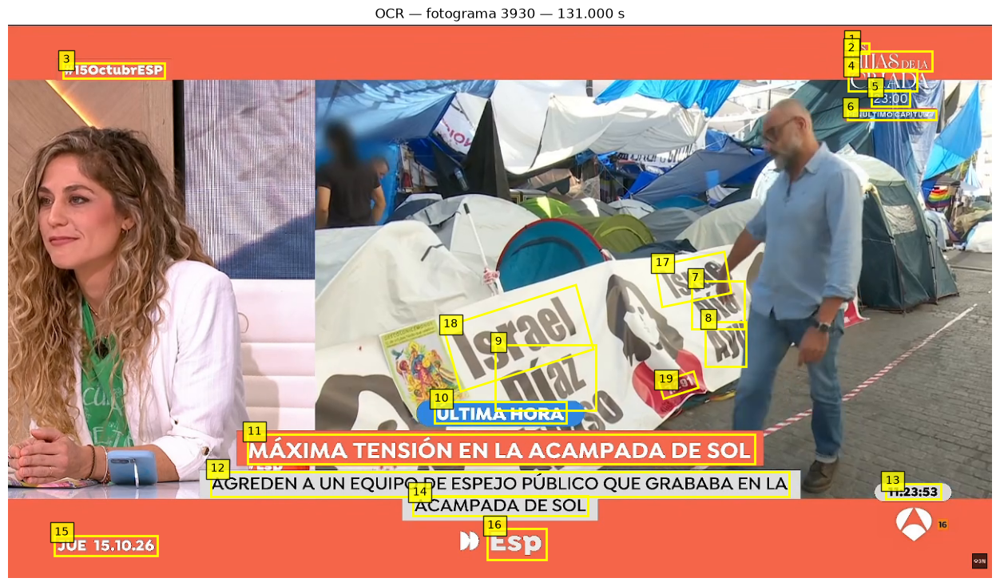

,bloque,texto,score_ocr
0,1,LAS,0.573989
1,2,HIJASDELA,0.828616
2,3,#ISOctubrESP,0.349806
3,4,CRIAD,0.975083
4,5,23.00,0.561061
5,6,penultimo Capitula,0.108776
6,7,3(,0.043753
7,8,A},0.123858
8,9,aíal,0.021493
9,10,ÚLTIMA HORA,0.994457


Resultados guardados en: /workspace/equipo5/PAULA/resultados


In [17]:
from pathlib import Path
import subprocess
import json
import cv2
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

base = Path("/workspace/equipo5/PAULA")
python_ocr = base / "entorno_ocr/bin/python"
resultados = base / "resultados"
resultados.mkdir(exist_ok=True)

# 1. Leer un fotograma del vídeo
cap = cv2.VideoCapture(str(base / "prueba_01.mp4"))

try:
    if not cap.isOpened():
        raise RuntimeError("No se puede abrir el vídeo.")

    fps = cap.get(cv2.CAP_PROP_FPS)
    if fps <= 0:
        raise RuntimeError("No se pudo obtener la frecuencia del vídeo.")

    cap.set(cv2.CAP_PROP_POS_FRAMES, round(131 * fps))
    ok, imagen = cap.read()

    if not ok:
        raise RuntimeError("No se pudo leer el fotograma.")

    frame_index = int(round(cap.get(cv2.CAP_PROP_POS_FRAMES))) - 1
    timestamp_s = cap.get(cv2.CAP_PROP_POS_MSEC) / 1000

finally:
    cap.release()

imagen_path = resultados / "fotograma_ocr.png"
json_path = resultados / "ocr_fotograma.json"

if not cv2.imwrite(str(imagen_path), imagen):
    raise RuntimeError("No se pudo guardar el fotograma.")

# 2. Ejecutar OCR desde su entorno separado
codigo_ocr = """
import sys
import json
from pathlib import Path
import easyocr

imagen_path, json_path, carpeta_modelos = sys.argv[1:]

reader = easyocr.Reader(
    ['es', 'en'],
    gpu='cuda:0',
    model_storage_directory=carpeta_modelos,
    user_network_directory=str(Path(carpeta_modelos) / 'user_network'),
)

lecturas = reader.readtext(imagen_path, detail=1, paragraph=False)

datos = [
    {
        'poligono': [[float(x), float(y)] for x, y in caja],
        'texto': texto,
        'score_ocr': float(score),
    }
    for caja, texto, score in lecturas
]

Path(json_path).write_text(
    json.dumps(datos, ensure_ascii=False, indent=2),
    encoding='utf-8',
)
print(f'Bloques de texto detectados: {len(datos)}')
"""

proceso = subprocess.run(
    [
        str(python_ocr), "-",
        str(imagen_path),
        str(json_path),
        str(base / "modelos_cache/easyocr"),
    ],
    input=codigo_ocr,
    capture_output=True,
    text=True,
)

print(proceso.stdout)

if proceso.returncode != 0:
    print(proceso.stderr[-6000:])
    raise RuntimeError("El OCR ha fallado; comparte el error mostrado.")

# 3. Mostrar texto, posición y tiempo
datos = json.loads(json_path.read_text(encoding="utf-8"))

filas = []
fig, ax = plt.subplots(figsize=(16, 9))
ax.imshow(cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB))

for numero, dato in enumerate(datos, start=1):
    puntos = dato["poligono"]

    ax.add_patch(Polygon(
        puntos, closed=True,
        fill=False, edgecolor="yellow", linewidth=2,
    ))
    ax.text(
        puntos[0][0], max(12, puntos[0][1]),
        str(numero),
        color="black",
        bbox=dict(facecolor="yellow", alpha=0.8),
    )

    filas.append({
        "video_id": "prueba_01",
        "frame_index": frame_index,
        "timestamp_s": timestamp_s,
        "timestamp_source": "opencv_pos_msec",
        "bloque": numero,
        "texto": dato["texto"],
        "score_ocr": dato["score_ocr"],
        "poligono_px": json.dumps(puntos),
        "estado_revision": "pendiente",
    })

ax.set_title(f"OCR — fotograma {frame_index} — {timestamp_s:.3f} s")
ax.axis("off")
plt.show()

columnas = [
    "video_id", "frame_index", "timestamp_s", "timestamp_source",
    "bloque", "texto", "score_ocr", "poligono_px", "estado_revision",
]
tabla_ocr = pd.DataFrame(filas, columns=columnas)

tabla_ocr.to_csv(
    resultados / "ocr_fotograma.csv",
    index=False,
)

display(tabla_ocr[["bloque", "texto", "score_ocr"]])
print("Resultados guardados en:", resultados)

In [18]:
import json
import pandas as pd

alto, ancho = imagen.shape[:2]
seleccionados = []

for _, fila in tabla_ocr.iterrows():
    puntos = json.loads(fila["poligono_px"])
    centro_x = sum(p[0] for p in puntos) / len(puntos)
    centro_y = sum(p[1] for p in puntos) / len(puntos)

    # Región aproximada de titulares y subtítulos en ESTE vídeo.
    dentro_franja = (
        0.18 <= centro_x / ancho <= 0.90
        and 0.67 <= centro_y / alto <= 0.89
    )

    if dentro_franja:
        registro = fila.to_dict()
        registro["centro_y"] = centro_y
        registro["centro_x"] = centro_x
        registro["tipo_provisional"] = "rotulo_inferior"
        registro["requiere_revision"] = fila["score_ocr"] < 0.60
        seleccionados.append(registro)

if seleccionados:
    tabla_rotulos = (
        pd.DataFrame(seleccionados)
        .sort_values(["centro_y", "centro_x"])
        .reset_index(drop=True)
    )

    tabla_rotulos.to_csv(
        resultados / "rotulos_fotograma.csv",
        index=False,
    )

    with pd.option_context("display.max_colwidth", None):
        display(tabla_rotulos[
            ["timestamp_s", "texto", "score_ocr", "requiere_revision"]
        ])
else:
    print("No se encontraron textos dentro de la franja seleccionada.")

,timestamp_s,texto,score_ocr,requiere_revision
0,131.0,ÚLTIMA HORA,0.994457,False
1,131.0,MÁXIMA TENSIÓN EN LA ACAMPADA DE SOL,0.859527,False
2,131.0,AGREDEN A UN EQUIPO DE ESPEJO PÚBLICO QUE GRABABA EN LA,0.798771,False
3,131.0,ACAMPADA DE SOL,0.940345,False


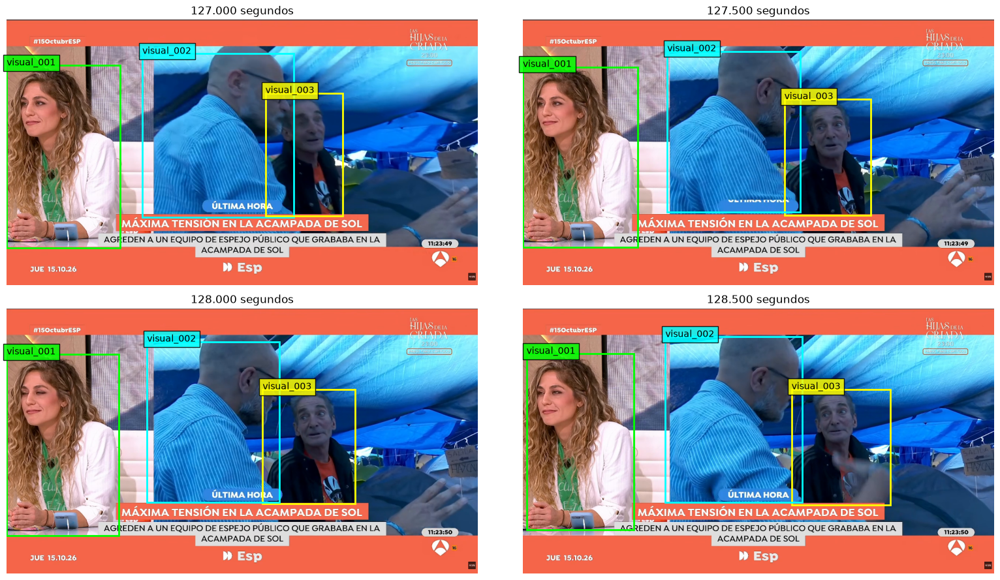

Fotogramas procesados: 60
Identificadores generados: 4
CSV guardado en: /workspace/equipo5/PAULA/resultados/seguimiento_127_129s.csv


In [19]:
import cv2
import torch
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from pathlib import Path

# Comparar cuánto se solapan dos rectángulos.
def calcular_iou(a, b):
    izquierda = max(a[0], b[0])
    arriba = max(a[1], b[1])
    derecha = min(a[2], b[2])
    abajo = min(a[3], b[3])

    interseccion = max(0, derecha - izquierda) * max(0, abajo - arriba)
    area_a = max(0, a[2] - a[0]) * max(0, a[3] - a[1])
    area_b = max(0, b[2] - b[0]) * max(0, b[3] - b[1])
    union = area_a + area_b - interseccion

    return interseccion / union if union > 0 else 0.0


base = Path("/workspace/equipo5/PAULA")
salida = base / "resultados"
salida.mkdir(exist_ok=True)

cap = cv2.VideoCapture(str(base / "prueba_01.mp4"))
if not cap.isOpened():
    raise RuntimeError("No se puede abrir el vídeo.")

fps = cap.get(cv2.CAP_PROP_FPS)
if fps <= 0:
    cap.release()
    raise RuntimeError("No se pudo obtener la frecuencia del vídeo.")

inicio_frame = round(127 * fps)
fin_frame = round(129 * fps)

anteriores = {}
siguiente_id = 1
filas = []
resumen = []
muestras = []
umbral_iou = 0.30

try:
    # Avanzar desde el inicio manteniendo el índice de fotograma.
    for frame_index in range(fin_frame):
        if frame_index < inicio_frame:
            if not cap.grab():
                raise RuntimeError("El vídeo terminó antes de la muestra.")
            continue

        ok, frame = cap.read()
        if not ok:
            raise RuntimeError(f"Error leyendo el fotograma {frame_index}.")

        tiempo = cap.get(cv2.CAP_PROP_POS_MSEC) / 1000
        alto, ancho = frame.shape[:2]
        rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

        tensor = (
            torch.from_numpy(rgb.copy())
            .permute(2, 0, 1)
            .float() / 255.0
        )

        with torch.inference_mode():
            pred = modelo_visual([tensor.to(dispositivo)])[0]

        filtro = (
            (pred["labels"] == clase_persona)
            & (pred["scores"] >= 0.70)
        )
        cajas = pred["boxes"][filtro].cpu().numpy()
        scores = pred["scores"][filtro].cpu().numpy()

        # Buscar asociaciones con el fotograma inmediatamente anterior.
        candidatos = []
        for identificador, caja_anterior in anteriores.items():
            for j, caja in enumerate(cajas):
                coincidencia = calcular_iou(caja_anterior, caja)
                if coincidencia >= umbral_iou:
                    candidatos.append((coincidencia, identificador, j))

        asignaciones = {}
        usados = set()

        for coincidencia, identificador, j in sorted(
            candidatos, reverse=True
        ):
            if identificador not in usados and j not in asignaciones:
                asignaciones[j] = identificador
                usados.add(identificador)

        actuales = {}
        dibujo = []

        for j, (caja, score) in enumerate(zip(cajas, scores)):
            identificador = asignaciones.get(j)

            if identificador is None:
                identificador = siguiente_id
                siguiente_id += 1

            actuales[identificador] = caja
            x1, y1, x2, y2 = map(float, caja)
            etiqueta = f"visual_{identificador:03d}"

            filas.append({
                "video_id": "prueba_01",
                "segmento_id": "prueba_127_129",
                "frame_index": frame_index,
                "timestamp_s": tiempo,
                "track_id": etiqueta,
                "x1": x1, "y1": y1,
                "x2": x2, "y2": y2,
                "bbox_area_pct": (
                    100 * (x2 - x1) * (y2 - y1) / (ancho * alto)
                ),
                "detection_score": float(score),
                "estado_revision": "pendiente",
            })
            dibujo.append((etiqueta, caja.copy(), identificador))

        # Si se pierde una detección, no inventamos su continuidad.
        anteriores = actuales

        resumen.append({
            "frame_index": frame_index,
            "timestamp_s": tiempo,
            "detecciones": len(cajas),
        })

        # Guardar cuatro imágenes para revisar los identificadores.
        if (frame_index - inicio_frame) % 15 == 0:
            muestras.append((tiempo, rgb.copy(), dibujo))

finally:
    cap.release()

columnas = [
    "video_id", "segmento_id", "frame_index", "timestamp_s", "track_id",
    "x1", "y1", "x2", "y2", "bbox_area_pct",
    "detection_score", "estado_revision",
]
tabla_seguimiento = pd.DataFrame(filas, columns=columnas)
tabla_seguimiento.to_csv(
    salida / "seguimiento_127_129s.csv", index=False
)
pd.DataFrame(resumen).to_csv(
    salida / "fotogramas_seguimiento_127_129s.csv", index=False
)

fig, ejes = plt.subplots(2, 2, figsize=(16, 9))
colores = ["lime", "cyan", "yellow", "magenta", "orange"]

for ax in ejes.flat:
    ax.axis("off")

for ax, (tiempo, rgb, dibujo) in zip(ejes.flat, muestras):
    ax.imshow(rgb)

    for etiqueta, caja, identificador in dibujo:
        x1, y1, x2, y2 = caja
        color = colores[(identificador - 1) % len(colores)]

        ax.add_patch(Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            fill=False, edgecolor=color, linewidth=2,
        ))
        ax.text(
            x1, max(12, y1), etiqueta,
            color="black",
            bbox=dict(facecolor=color, alpha=0.85),
        )

    ax.set_title(f"{tiempo:.3f} segundos")

plt.tight_layout()
plt.show()

print("Fotogramas procesados:", len(resumen))
print("Identificadores generados:", tabla_seguimiento["track_id"].nunique())
print("CSV guardado en:", salida / "seguimiento_127_129s.csv")

In [20]:
from pathlib import Path
import pandas as pd
import numpy as np

carpeta = Path("/workspace/equipo5/PAULA/resultados")

seguimiento = pd.read_csv(carpeta / "seguimiento_127_129s.csv")
fotogramas = pd.read_csv(
    carpeta / "fotogramas_seguimiento_127_129s.csv"
).sort_values("frame_index")

# Validar esta muestra, cuyo vídeo declara 30 FPS.
fps_muestra = 30.0

if fotogramas.empty or seguimiento.empty:
    raise ValueError("La muestra no contiene fotogramas o detecciones.")

if fotogramas["frame_index"].duplicated().any():
    raise ValueError("Hay fotogramas duplicados.")

if seguimiento.duplicated(["frame_index", "track_id"]).any():
    raise ValueError("Un identificador aparece duplicado en un fotograma.")

if not seguimiento["frame_index"].isin(fotogramas["frame_index"]).all():
    raise ValueError("Hay detecciones sin fotograma correspondiente.")

if not (
    fotogramas["frame_index"].diff().dropna().eq(1).all()
    and np.allclose(
        fotogramas["timestamp_s"].diff().dropna(),
        1 / fps_muestra,
        atol=0.001,
    )
):
    raise ValueError("La secuencia temporal necesita revisión.")

resumen_visual = seguimiento.groupby("track_id").agg(
    primer_instante_observado_s=("timestamp_s", "min"),
    ultimo_instante_observado_s=("timestamp_s", "max"),
    fotogramas_detectado=("frame_index", "nunique"),
    ocupacion_media_pct=("bbox_area_pct", "mean"),
    ocupacion_maxima_pct=("bbox_area_pct", "max"),
).reset_index()

# Tiempo representado por los fotogramas con detección.
resumen_visual["tiempo_detectado_muestra_s"] = (
    resumen_visual["fotogramas_detectado"] / fps_muestra
)

resumen_visual["cobertura_muestra_pct"] = (
    100 * resumen_visual["fotogramas_detectado"] / len(fotogramas)
)

resumen_visual["estado_revision"] = "pendiente"

resumen_visual.to_csv(
    carpeta / "resumen_visual_127_129s.csv",
    index=False,
)

display(resumen_visual.round(3))
print("Resumen guardado.")

,track_id,primer_instante_observado_s,ultimo_instante_observado_s,fotogramas_detectado,ocupacion_media_pct,ocupacion_maxima_pct,tiempo_detectado_muestra_s,cobertura_muestra_pct,estado_revision
0,visual_001,127.000,128.967,60,16.490,16.771,2.000,100.000,pendiente
1,visual_002,127.000,128.967,60,17.812,19.855,2.000,100.000,pendiente
2,visual_003,127.000,128.967,60,8.222,9.853,2.000,100.000,pendiente
3,visual_004,128.933,128.933,1,4.033,4.033,0.033,1.667,pendiente


Resumen guardado.


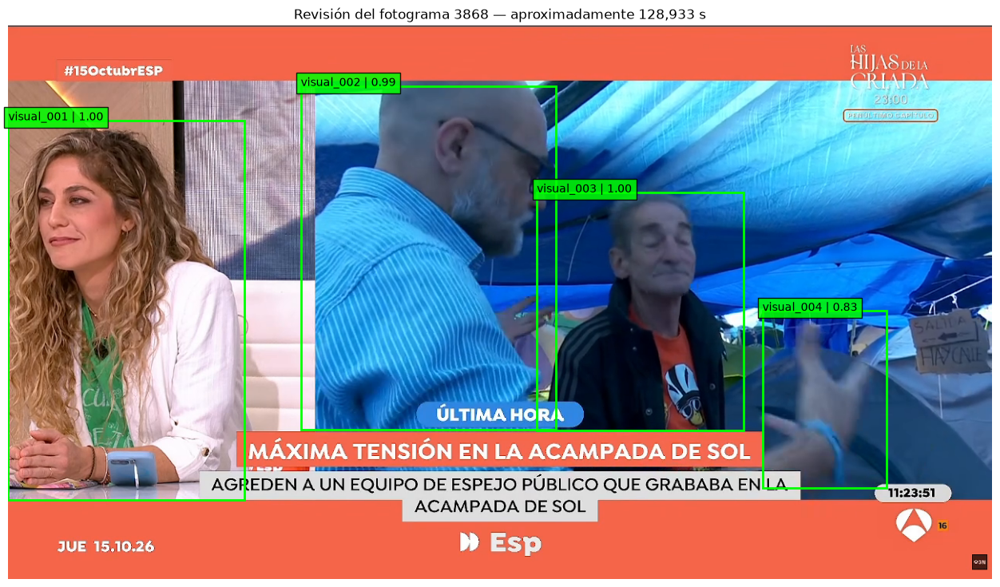

,track_id,timestamp_s,detection_score,bbox_area_pct
174,visual_001,128.933333,0.998044,16.433747
175,visual_003,128.933333,0.995896,9.059996
176,visual_002,128.933333,0.985058,16.071607
177,visual_004,128.933333,0.830178,4.033158


In [21]:
from pathlib import Path
import cv2
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

base = Path("/workspace/equipo5/PAULA")
datos = pd.read_csv(base / "resultados/seguimiento_127_129s.csv")

fotograma_objetivo = 3868
detecciones = datos[datos["frame_index"] == fotograma_objetivo]

cap = cv2.VideoCapture(str(base / "prueba_01.mp4"))

try:
    cap.set(cv2.CAP_PROP_POS_FRAMES, fotograma_objetivo)
    ok, imagen_revision = cap.read()
    if not ok:
        raise RuntimeError("No se pudo leer el fotograma.")
finally:
    cap.release()

fig, ax = plt.subplots(figsize=(16, 9))
ax.imshow(cv2.cvtColor(imagen_revision, cv2.COLOR_BGR2RGB))

for _, fila in detecciones.iterrows():
    ax.add_patch(Rectangle(
        (fila["x1"], fila["y1"]),
        fila["x2"] - fila["x1"],
        fila["y2"] - fila["y1"],
        fill=False, edgecolor="lime", linewidth=2,
    ))
    ax.text(
        fila["x1"], max(15, fila["y1"]),
        f'{fila["track_id"]} | {fila["detection_score"]:.2f}',
        color="black",
        bbox=dict(facecolor="lime", alpha=0.85),
    )

ax.set_title("Revisión del fotograma 3868 — aproximadamente 128,933 s")
ax.axis("off")
plt.show()

display(detecciones[
    ["track_id", "timestamp_s", "detection_score", "bbox_area_pct"]
])

In [22]:
from pathlib import Path
import pandas as pd

carpeta = Path("/workspace/equipo5/PAULA/resultados")
ruta_etiquetas = carpeta / "etiquetas_participantes_127_129s.csv"

seguimiento = pd.read_csv(carpeta / "seguimiento_127_129s.csv")

# No sobrescribir las etiquetas si ya las has rellenado.
if ruta_etiquetas.exists():
    etiquetas = pd.read_csv(ruta_etiquetas, keep_default_na=False)
else:
    etiquetas = (
        seguimiento[["video_id", "segmento_id", "track_id"]]
        .drop_duplicates()
        .sort_values("track_id")
        .reset_index(drop=True)
    )

    etiquetas["participante_id"] = ""
    etiquetas["genero_documentado"] = "no determinado"
    etiquetas["fuente_genero"] = ""
    etiquetas["estado_revision"] = "pendiente"
    etiquetas["observaciones"] = ""

    etiquetas.to_csv(ruta_etiquetas, index=False)

display(etiquetas)
print("Guardado en:", ruta_etiquetas)

,video_id,segmento_id,track_id,participante_id,genero_documentado,fuente_genero,estado_revision,observaciones
0,prueba_01,prueba_127_129,visual_001,,no determinado,,pendiente,
1,prueba_01,prueba_127_129,visual_002,,no determinado,,pendiente,
2,prueba_01,prueba_127_129,visual_003,,no determinado,,pendiente,
3,prueba_01,prueba_127_129,visual_004,,no determinado,,pendiente,


Guardado en: /workspace/equipo5/PAULA/resultados/etiquetas_participantes_127_129s.csv


In [ ]:
#generamos parte de HOMBRE MUJER

In [25]:
from pathlib import Path
import subprocess
import sys

base = Path("/workspace/equipo5/PAULA")
entorno_genero = base / "entorno_genero"
python_genero = entorno_genero / "bin" / "python"

if not python_genero.exists():
    subprocess.run(
        [sys.executable, "-m", "venv", "--system-site-packages", str(entorno_genero)],
        check=True,
    )

instalacion = subprocess.run(
    [str(python_genero), "-m", "pip", "install",
     "--disable-pip-version-check", "deepface", "tf-keras"],
    stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
)
print(instalacion.stdout[-6000:])

if instalacion.returncode != 0:
    print("\n❌ La instalación no se ha completado. Comparte el error.")
else:
    comprobacion = subprocess.run(
        [str(python_genero), "-c",
         "import deepface; print('DeepFace instalado')"],
        capture_output=True, text=True,
    )
    print(comprobacion.stdout, comprobacion.stderr[-1500:])

uirement already satisfied: absl-py>=1.0.0 in ./entorno_genero/lib/python3.13/site-packages (from tensorflow<2.22,>=2.21->tf-keras) (2.5.1)

DeepFace instalado
 


In [26]:
from pathlib import Path
import subprocess
import json
import cv2
import pandas as pd

base = Path("/workspace/equipo5/PAULA")
resultados = base / "resultados"
python_genero = base / "entorno_genero/bin/python"
carpeta_crops = resultados / "crops_genero"
carpeta_crops.mkdir(exist_ok=True)

# --- 1. Elegir una muestra de fotogramas por persona ---------------
paso = 5            # un fotograma de cada 5 por track
max_por_track = 12  # máximo de recortes por track

seguimiento = pd.read_csv(resultados / "seguimiento_127_129s.csv")
muestra = seguimiento.sort_values(["track_id", "frame_index"])
muestra = muestra[muestra.groupby("track_id").cumcount() % paso == 0]
muestra = muestra[muestra.groupby("track_id").cumcount() < max_por_track]
muestra = muestra.reset_index(drop=True)

por_frame = {f: g for f, g in muestra.groupby("frame_index")}

# --- 2. Recortar cada persona del vídeo ----------------------------
registros = []
cap = cv2.VideoCapture(str(base / "prueba_01.mp4"))

try:
    if not cap.isOpened():
        raise RuntimeError("No se puede abrir el vídeo.")

    primero, ultimo = min(por_frame), max(por_frame)

    # Leer desde el inicio para mantener el índice de fotograma.
    for frame_index in range(ultimo + 1):
        if frame_index < primero:
            if not cap.grab():
                raise RuntimeError("El vídeo terminó antes de la muestra.")
            continue

        ok, frame = cap.read()
        if not ok:
            raise RuntimeError(f"Error leyendo el fotograma {frame_index}.")

        if frame_index not in por_frame:
            continue

        alto, ancho = frame.shape[:2]
        for _, fila in por_frame[frame_index].iterrows():
            x1, x2 = int(max(0, fila["x1"])), int(min(ancho, fila["x2"]))
            y1, y2 = int(max(0, fila["y1"])), int(min(alto, fila["y2"]))
            recorte = frame[y1:y2, x1:x2]
            if recorte.size == 0:
                continue

            ruta = carpeta_crops / f"{fila['track_id']}_f{frame_index}.png"
            cv2.imwrite(str(ruta), recorte)
            registros.append({
                "track_id": fila["track_id"],
                "frame_index": int(frame_index),
                "ruta": str(ruta),
            })
finally:
    cap.release()

entrada_json = resultados / "crops_genero.json"
salida_json = resultados / "genero_crudo.json"
entrada_json.write_text(json.dumps(registros), encoding="utf-8")

# --- 3. Ejecutar DeepFace en su entorno ----------------------------
codigo_genero = """
import sys, json, os
from pathlib import Path

entrada, salida, carpeta_pesos = sys.argv[1:4]
os.environ['DEEPFACE_HOME'] = carpeta_pesos
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
from deepface import DeepFace

items = json.loads(Path(entrada).read_text(encoding='utf-8'))
salida_items = []

for item in items:
    registro = dict(item)
    try:
        r = DeepFace.analyze(
            img_path=item['ruta'],
            actions=['age', 'gender'],   # sin raza/etnia
            detector_backend='retinaface',
            enforce_detection=True,
            silent=True,
        )[0]
        registro.update(
            estado='cara_detectada',
            edad_estimada=float(r['age']),
            prob_hombre=float(r['gender']['Man']),
            prob_mujer=float(r['gender']['Woman']),
        )
    except ValueError:
        registro['estado'] = 'sin_cara_detectada'
    except Exception as e:
        registro['estado'] = 'error: ' + type(e).__name__
    salida_items.append(registro)

Path(salida).write_text(json.dumps(salida_items), encoding='utf-8')
print(f'Recortes analizados: {len(salida_items)}')
"""

proceso = subprocess.run(
    [str(python_genero), "-", str(entrada_json), str(salida_json),
     str(base / "modelos_cache/deepface")],
    input=codigo_genero, capture_output=True, text=True,
)
print(proceso.stdout)
if proceso.returncode != 0:
    print(proceso.stderr[-6000:])
    raise RuntimeError("DeepFace ha fallado; comparte el error mostrado.")

# --- 4. Agregar por track_id ---------------------------------------
tabla = pd.DataFrame(json.loads(salida_json.read_text(encoding="utf-8")))
tabla.to_csv(resultados / "genero_por_recorte_127_129s.csv", index=False)

con_cara = tabla[tabla["estado"] == "cara_detectada"]

resumen = (
    tabla.groupby("track_id")
    .agg(recortes_analizados=("ruta", "count"))
    .reset_index()
)

if not con_cara.empty:
    agregado = (
        con_cara.groupby("track_id")
        .agg(
            recortes_con_cara=("frame_index", "count"),
            prob_mujer_media=("prob_mujer", "mean"),
            edad_media_estimada=("edad_estimada", "mean"),
        )
        .reset_index()
    )
    resumen = resumen.merge(agregado, on="track_id", how="left")
else:
    resumen["recortes_con_cara"] = 0
    resumen["prob_mujer_media"] = float("nan")
    resumen["edad_media_estimada"] = float("nan")

def clasificar(p):
    if pd.isna(p):
        return "sin_datos"
    if p >= 60:
        return "mujer"
    if p <= 40:
        return "hombre"
    return "indeterminado"

resumen["genero_aparente_estimado"] = resumen["prob_mujer_media"].apply(clasificar)
resumen["fuente"] = "estimacion_deepface"
resumen["estado_revision"] = "pendiente"

resumen.to_csv(resultados / "genero_estimado_127_129s.csv", index=False)
display(resumen.round(1))
print("Guardado en:", resultados / "genero_estimado_127_129s.csv")

26-10-17 15:57:38 - Directory /workspace/equipo5/PAULA/modelos_cache/deepface/.deepface has been created
26-10-17 15:57:38 - Directory /workspace/equipo5/PAULA/modelos_cache/deepface/.deepface/weights has been created
26-10-17 15:57:40 - retinaface.h5 will be downloaded from the url https://github.com/serengil/deepface_models/releases/download/v1.0/retinaface.h5
26-10-17 15:57:46 - 🔗 age_model_weights.h5 will be downloaded from https://github.com/serengil/deepface_models/releases/download/v1.0/age_model_weights.h5 to /workspace/equipo5/PAULA/modelos_cache/deepface/.deepface/weights/age_model_weights.h5...
26-10-17 15:57:49 - 🔗 gender_model_weights.h5 will be downloaded from https://github.com/serengil/deepface_models/releases/download/v1.0/gender_model_weights.h5 to /workspace/equipo5/PAULA/modelos_cache/deepface/.deepface/weights/gender_model_weights.h5...
Recortes analizados: 37



,track_id,recortes_analizados,recortes_con_cara,prob_mujer_media,edad_media_estimada,genero_aparente_estimado,fuente,estado_revision
0,visual_001,12,12.0,99.2,36.9,mujer,estimacion_deepface,pendiente
1,visual_002,12,12.0,23.5,35.0,hombre,estimacion_deepface,pendiente
2,visual_003,12,12.0,2.9,41.7,hombre,estimacion_deepface,pendiente
3,visual_004,1,NaN,NaN,NaN,sin_datos,estimacion_deepface,pendiente


Guardado en: /workspace/equipo5/PAULA/resultados/genero_estimado_127_129s.csv


In [35]:


# COMBINACION OUTPUTS OCR Y GENERO

print("hecho")

hecho


In [36]:
from pathlib import Path
import json
import cv2
import torch
import pandas as pd
from torchvision.models.detection import (
    fasterrcnn_mobilenet_v3_large_320_fpn,
    FasterRCNN_MobileNet_V3_Large_320_FPN_Weights,
)

base = Path("/workspace/equipo5/PAULA")
video_path = base / "prueba_01.mp4"
salida = base / "resultados" / "video_completo"
carpeta_crops = salida / "crops"
carpeta_crops.mkdir(parents=True, exist_ok=True)

# ---- Parámetros ----
limite_s = None           # None = vídeo completo
muestras_por_segundo = 10
umbral = 0.70
umbral_iou = 0.25
crop_cada_n_muestras = 10   # ~1 recorte por segundo y persona
max_crops_por_track = 8
guardar_cada = 100          # muestras entre guardados (~10 s de vídeo)

ruta_det = salida / "detecciones.csv"
ruta_crops = salida / "crops_index.csv"
ruta_prog = salida / "progreso_deteccion.json"

# ---- Modelo (se reutiliza si ya está cargado) ----
if "modelo_visual" not in globals():
    torch.hub.set_dir(str(base / "modelos_cache"))
    pesos = FasterRCNN_MobileNet_V3_Large_320_FPN_Weights.COCO_V1
    dispositivo = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
    modelo_visual = fasterrcnn_mobilenet_v3_large_320_fpn(
        weights=pesos
    ).to(dispositivo).eval()
    clase_persona = pesos.meta["categories"].index("person")


def calcular_iou(a, b):
    izq, arr = max(a[0], b[0]), max(a[1], b[1])
    der, aba = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, der - izq) * max(0, aba - arr)
    area_a = max(0, a[2] - a[0]) * max(0, a[3] - a[1])
    area_b = max(0, b[2] - b[0]) * max(0, b[3] - b[1])
    union = area_a + area_b - inter
    return inter / union if union > 0 else 0.0


# ---- Retomar progreso si existe ----
if ruta_prog.exists():
    prog = json.loads(ruta_prog.read_text(encoding="utf-8"))
    print("Retomando desde el fotograma", prog["ultimo_frame"] + 1)
else:
    prog = {
        "ultimo_frame": -1, "siguiente_id": 1, "anteriores": {},
        "n_por_track": {}, "crops_por_track": {},
        "fps": None, "paso": None,
    }

cap = cv2.VideoCapture(str(video_path))
if not cap.isOpened():
    raise RuntimeError("No se puede abrir el vídeo.")

fps = cap.get(cv2.CAP_PROP_FPS)
total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
if fps <= 0:
    cap.release()
    raise RuntimeError("No se pudo obtener la frecuencia del vídeo.")

paso = max(1, round(fps / muestras_por_segundo))
prog["fps"], prog["paso"] = fps, paso
frame_final = total if limite_s is None else min(total, int(limite_s * fps))

anteriores = {int(k): v for k, v in prog["anteriores"].items()}
buffer_det, buffer_crops = [], []


def volcar():
    """Guarda en disco lo acumulado y el estado del seguimiento."""
    global buffer_det, buffer_crops
    if buffer_det:
        pd.DataFrame(buffer_det).to_csv(
            ruta_det, mode="a", index=False, header=not ruta_det.exists()
        )
    if buffer_crops:
        pd.DataFrame(buffer_crops).to_csv(
            ruta_crops, mode="a", index=False, header=not ruta_crops.exists()
        )
    prog["anteriores"] = {str(k): v for k, v in anteriores.items()}
    tmp = ruta_prog.with_suffix(".tmp")
    tmp.write_text(json.dumps(prog), encoding="utf-8")
    tmp.replace(ruta_prog)
    buffer_det, buffer_crops = [], []


try:
    inicio = prog["ultimo_frame"] + 1
    for _ in range(inicio):          # avanzar sin decodificar
        if not cap.grab():
            raise RuntimeError("El vídeo terminó antes del punto de reanudación.")

    muestras_buffer = 0
    for frame_index in range(inicio, frame_final):
        if frame_index % paso != 0:
            if not cap.grab():
                break
            continue

        ok, frame = cap.read()
        if not ok:
            break

        alto, ancho = frame.shape[:2]
        rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        tensor = torch.from_numpy(rgb.copy()).permute(2, 0, 1).float() / 255.0

        with torch.inference_mode():
            pred = modelo_visual([tensor.to(dispositivo)])[0]

        filtro = (pred["labels"] == clase_persona) & (pred["scores"] >= umbral)
        cajas = pred["boxes"][filtro].cpu().numpy()
        scores = pred["scores"][filtro].cpu().numpy()

        # Asociar con el muestreo anterior por solapamiento (IoU)
        candidatos = []
        for ident, caja_ant in anteriores.items():
            for j, caja in enumerate(cajas):
                iou = calcular_iou(caja_ant, caja)
                if iou >= umbral_iou:
                    candidatos.append((iou, ident, j))

        asignaciones, usados = {}, set()
        for iou, ident, j in sorted(candidatos, reverse=True):
            if ident not in usados and j not in asignaciones:
                asignaciones[j] = ident
                usados.add(ident)

        actuales = {}
        for j, (caja, score) in enumerate(zip(cajas, scores)):
            ident = asignaciones.get(j)
            if ident is None:
                ident = prog["siguiente_id"]
                prog["siguiente_id"] += 1
            actuales[ident] = [float(v) for v in caja]

            x1, y1, x2, y2 = actuales[ident]
            x1, x2 = max(0, x1), min(ancho, x2)
            y1, y2 = max(0, y1), min(alto, y2)
            tid = f"visual_{ident:04d}"

            buffer_det.append({
                "video_id": video_path.stem,
                "frame_index": frame_index,
                "timestamp_s": round(frame_index / fps, 3),
                "track_id": tid,
                "x1": x1, "y1": y1, "x2": x2, "y2": y2,
                "bbox_area_pct": 100 * (x2 - x1) * (y2 - y1) / (ancho * alto),
                "detection_score": float(score),
            })

            # Guardar algún recorte por persona para estimar género/edad
            n = prog["n_por_track"].get(tid, 0)
            prog["n_por_track"][tid] = n + 1
            hechos = prog["crops_por_track"].get(tid, 0)
            if n % crop_cada_n_muestras == 0 and hechos < max_crops_por_track:
                recorte = frame[int(y1):int(y2), int(x1):int(x2)]
                if recorte.size and min(recorte.shape[:2]) >= 40:
                    ruta = carpeta_crops / f"{tid}_f{frame_index}.png"
                    cv2.imwrite(str(ruta), recorte)
                    prog["crops_por_track"][tid] = hechos + 1
                    buffer_crops.append({
                        "track_id": tid,
                        "frame_index": frame_index,
                        "ruta": str(ruta),
                    })

        anteriores = actuales
        prog["ultimo_frame"] = frame_index
        muestras_buffer += 1

        if muestras_buffer % guardar_cada == 0:
            volcar()
            print(f"Guardado hasta {frame_index / fps:.1f} s")
finally:
    cap.release()
    volcar()

print("Hecho. Último fotograma procesado:", prog["ultimo_frame"],
      f"({prog['ultimo_frame'] / fps:.1f} s)")

Retomando desde el fotograma 598
Guardado hasta 29.9 s
Guardado hasta 39.9 s
Guardado hasta 49.9 s
Guardado hasta 59.9 s
Guardado hasta 69.9 s
Guardado hasta 79.9 s
Guardado hasta 89.9 s
Guardado hasta 99.9 s
Guardado hasta 109.9 s
Guardado hasta 119.9 s
Guardado hasta 129.9 s
Guardado hasta 139.9 s
Guardado hasta 149.9 s
Guardado hasta 159.9 s
Guardado hasta 169.9 s
Guardado hasta 179.9 s
Guardado hasta 189.9 s
Guardado hasta 199.9 s
Guardado hasta 209.9 s
Guardado hasta 219.9 s
Guardado hasta 229.9 s
Guardado hasta 239.9 s
Guardado hasta 249.9 s
Guardado hasta 259.9 s
Hecho. Último fotograma procesado: 7869 (262.3 s)


In [37]:
from pathlib import Path
import subprocess
import json
import pandas as pd

base = Path("/workspace/equipo5/PAULA")
salida = base / "resultados" / "video_completo"
python_genero = base / "entorno_genero/bin/python"

crops = pd.read_csv(salida / "crops_index.csv")
entrada_json = salida / "crops_pendientes_genero.json"
entrada_json.write_text(
    json.dumps(crops.to_dict("records")), encoding="utf-8"
)
salida_jsonl = salida / "genero_crops.jsonl"

codigo_genero = r"""
import sys, json, os
from pathlib import Path

entrada, salida, carpeta_pesos = sys.argv[1:4]
os.environ['DEEPFACE_HOME'] = carpeta_pesos
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
from deepface import DeepFace

items = json.loads(Path(entrada).read_text(encoding='utf-8'))

hechos = set()
if Path(salida).exists():
    for linea in open(salida, encoding='utf-8'):
        hechos.add(json.loads(linea)['ruta'])

pendientes = [i for i in items if i['ruta'] not in hechos]
print(f'Pendientes: {len(pendientes)} de {len(items)}', flush=True)

with open(salida, 'a', encoding='utf-8') as f:
    for n, item in enumerate(pendientes, 1):
        registro = dict(item)
        try:
            r = DeepFace.analyze(
                img_path=item['ruta'],
                actions=['age', 'gender'],
                detector_backend='retinaface',
                enforce_detection=True,
                silent=True,
            )[0]
            registro.update(
                estado='cara_detectada',
                edad_estimada=float(r['age']),
                prob_hombre=float(r['gender']['Man']),
                prob_mujer=float(r['gender']['Woman']),
            )
        except ValueError:
            registro['estado'] = 'sin_cara_detectada'
        except Exception as e:
            registro['estado'] = 'error: ' + type(e).__name__
        f.write(json.dumps(registro) + '\n')
        f.flush()
        if n % 25 == 0:
            print(f'{n}/{len(pendientes)}', flush=True)
print('Terminado', flush=True)
"""

proceso = subprocess.Popen(
    [str(python_genero), "-", str(entrada_json), str(salida_jsonl),
     str(base / "modelos_cache/deepface")],
    stdin=subprocess.PIPE, stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT, text=True,
)
proceso.stdin.write(codigo_genero)
proceso.stdin.close()

for linea in proceso.stdout:
    if linea.startswith(("Pendientes", "Terminado")) or "/" in linea[:12]:
        print(linea.rstrip())

if proceso.wait() != 0:
    raise RuntimeError("DeepFace ha fallado; vuelve a lanzar la celda para reanudar.")

Pendientes: 509 de 555
25/509
50/509
75/509
100/509
125/509
150/509
175/509
200/509
225/509
250/509
275/509
300/509
325/509
350/509
375/509
400/509
425/509
450/509
475/509
500/509
Terminado


In [40]:
from pathlib import Path
import subprocess

base = Path("/workspace/equipo5/PAULA")
salida = base / "resultados" / "video_completo"
python_ocr = base / "entorno_ocr/bin/python"

limite_s = None       # None = vídeo completo
ocr_cada_s = 0.5

codigo_ocr = r"""
import sys, json
from pathlib import Path
import cv2
import easyocr

video, salida, carpeta_modelos, cada_s, limite = sys.argv[1:6]
cada_s = float(cada_s)
limite = None if limite == 'None' else float(limite)

hechos = set()
if Path(salida).exists():
    for linea in open(salida, encoding='utf-8'):
        hechos.add(json.loads(linea)['frame_index'])

cap = cv2.VideoCapture(video)
fps = cap.get(cv2.CAP_PROP_FPS)
total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
final = total if limite is None else min(total, int(limite * fps))
paso = max(1, round(cada_s * fps))

reader = easyocr.Reader(
    ['es', 'en'], gpu='cuda:0',
    model_storage_directory=carpeta_modelos,
    user_network_directory=str(Path(carpeta_modelos) / 'user_network'),
)

with open(salida, 'a', encoding='utf-8') as f:
    for frame_index in range(final):
        if frame_index % paso != 0 or frame_index in hechos:
            if not cap.grab():
                break
            continue
        if not cap.grab():
            break
        ok, frame = cap.retrieve()
        if not ok:
            break
        alto, ancho = frame.shape[:2]
        bloques = []
        for caja, texto, score in reader.readtext(frame, detail=1, paragraph=False):
            cx = sum(p[0] for p in caja) / 4 / ancho
            cy = sum(p[1] for p in caja) / 4 / alto
            bloques.append({
                'texto': texto, 'score_ocr': float(score),
                'centro_x_rel': cx, 'centro_y_rel': cy,
            })
        f.write(json.dumps({
            'frame_index': frame_index,
            'timestamp_s': round(frame_index / fps, 3),
            'bloques': bloques,
        }, ensure_ascii=False) + '\n')
        f.flush()
        if (frame_index // paso) % 20 == 0:
            print(f'OCR hasta {frame_index / fps:.1f} s', flush=True)
print('Terminado', flush=True)
"""

proceso = subprocess.Popen(
    [str(python_ocr), "-", str(base / "prueba_01.mp4"),
     str(salida / "ocr_video.jsonl"),
     str(base / "modelos_cache/easyocr"),
     str(ocr_cada_s), str(limite_s)],
    stdin=subprocess.PIPE, stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT, text=True,
)
proceso.stdin.write(codigo_ocr)
proceso.stdin.close()

for linea in proceso.stdout:
    if linea.startswith(("OCR", "Terminado")):
        print(linea.rstrip())

if proceso.wait() != 0:
    raise RuntimeError("El OCR ha fallado; vuelve a lanzar la celda para reanudar.")

OCR hasta 20.0 s
OCR hasta 30.0 s
OCR hasta 40.0 s
OCR hasta 50.0 s
OCR hasta 60.0 s
OCR hasta 70.0 s
OCR hasta 80.0 s
OCR hasta 90.0 s
OCR hasta 100.0 s
OCR hasta 110.0 s
OCR hasta 120.0 s
OCR hasta 130.0 s
OCR hasta 140.0 s
OCR hasta 150.0 s
OCR hasta 160.0 s
OCR hasta 170.0 s
OCR hasta 180.0 s
OCR hasta 190.0 s
OCR hasta 200.0 s
OCR hasta 210.0 s
OCR hasta 220.0 s
OCR hasta 230.0 s
OCR hasta 240.0 s
OCR hasta 250.0 s
OCR hasta 260.0 s
Terminado


In [41]:
from pathlib import Path
import json
import cv2
import pandas as pd

base = Path("/workspace/equipo5/PAULA")
salida = base / "resultados" / "video_completo"

cap = cv2.VideoCapture(str(base / "prueba_01.mp4"))
fps = cap.get(cv2.CAP_PROP_FPS)
total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
cap.release()
duracion = total / fps

prog = json.loads((salida / "progreso_deteccion.json").read_text())
hasta_det = prog["ultimo_frame"] / fps
det_ok = prog["ultimo_frame"] >= total - prog["paso"] - 1

crops = pd.read_csv(salida / "crops_index.csv")
ruta_gen = salida / "genero_crops.jsonl"
hechos_gen = (
    pd.read_json(ruta_gen, lines=True)["ruta"].nunique() if ruta_gen.exists() else 0
)
pend_gen = len(crops) - hechos_gen

ruta_ocr = salida / "ocr_video.jsonl"
hasta_ocr = 0.0
if ruta_ocr.exists():
    with open(ruta_ocr, encoding="utf-8") as f:
        for linea in f:
            hasta_ocr = json.loads(linea)["timestamp_s"]
ocr_ok = hasta_ocr >= duracion - 1

print(f"Duración del vídeo: {duracion:.1f} s ({total} fotogramas)")
print(f"1. Detección:  hasta {hasta_det:.1f} s  → {'COMPLETA' if det_ok else 'INCOMPLETA'}")
print(f"2. Género:     {hechos_gen}/{len(crops)} recortes  → "
      f"{'COMPLETO' if pend_gen == 0 else f'faltan {pend_gen}'}")
print(f"3. OCR:        hasta {hasta_ocr:.1f} s  → {'COMPLETO' if ocr_ok else 'INCOMPLETO'}")

if det_ok and pend_gen == 0 and ocr_ok:
    print("\n✅ Todo listo: puedes ejecutar la celda 4.")
else:
    print("\n⏳ Todavía falta algo: vuelve a lanzar la celda indicada.")

Duración del vídeo: 262.4 s (7871 fotogramas)
1. Detección:  hasta 262.3 s  → COMPLETA
2. Género:     555/555 recortes  → COMPLETO
3. OCR:        hasta 262.0 s  → COMPLETO

✅ Todo listo: puedes ejecutar la celda 4.


In [42]:
from pathlib import Path
import json
import pandas as pd

base = Path("/workspace/equipo5/PAULA")
salida = base / "resultados" / "video_completo"
ocr_cada_s = 0.5
franja_rotulo = dict(x=(0.18, 0.90), y=(0.67, 0.89))  # la de tu vídeo

prog = json.loads((salida / "progreso_deteccion.json").read_text(encoding="utf-8"))
fps, paso = prog["fps"], prog["paso"]

det = pd.read_csv(salida / "detecciones.csv")

# --- Género y edad por persona (media de sus recortes) ---
gen = pd.read_json(salida / "genero_crops.jsonl", lines=True)
con_cara = gen[gen["estado"] == "cara_detectada"]

por_track = (
    con_cara.groupby("track_id")
    .agg(
        recortes_con_cara=("frame_index", "count"),
        prob_mujer_media=("prob_mujer", "mean"),
        edad_media_estimada=("edad_estimada", "mean"),
    )
    .reset_index()
)

def clasificar(p):
    if pd.isna(p):
        return "sin_datos"
    if p >= 60:
        return "mujer"
    if p <= 40:
        return "hombre"
    return "indeterminado"

por_track["genero_aparente_estimado"] = por_track["prob_mujer_media"].apply(clasificar)

det = det.merge(por_track, on="track_id", how="left")
det["genero_aparente_estimado"] = det["genero_aparente_estimado"].fillna("sin_datos")

# --- Rótulos por instante (OCR) ---
filas_ocr = []
for linea in open(salida / "ocr_video.jsonl", encoding="utf-8"):
    d = json.loads(linea)
    textos = [
        b["texto"] for b in d["bloques"]
        if franja_rotulo["x"][0] <= b["centro_x_rel"] <= franja_rotulo["x"][1]
        and franja_rotulo["y"][0] <= b["centro_y_rel"] <= franja_rotulo["y"][1]
    ]
    filas_ocr.append({
        "timestamp_s": d["timestamp_s"],
        "rotulo_texto": " | ".join(textos),
        "otro_texto_en_pantalla": " | ".join(
            b["texto"] for b in d["bloques"] if b["texto"] not in textos
        ),
    })
ocr = pd.DataFrame(filas_ocr).sort_values("timestamp_s")

# --- Línea de tiempo: una fila cada 0,1 s ---
instantes = pd.DataFrame({
    "frame_index": range(0, prog["ultimo_frame"] + 1, paso)
})
instantes["timestamp_s"] = (instantes["frame_index"] / fps).round(3)

conteo = (
    det.pivot_table(
        index="frame_index", columns="genero_aparente_estimado",
        values="track_id", aggfunc="nunique", fill_value=0,
    )
    .reindex(columns=["mujer", "hombre", "indeterminado", "sin_datos"], fill_value=0)
    .reset_index()
    .rename(columns={
        "mujer": "n_mujeres", "hombre": "n_hombres",
        "indeterminado": "n_indeterminado", "sin_datos": "n_sin_datos",
    })
)

linea = instantes.merge(conteo, on="frame_index", how="left").fillna(0)
for c in ["n_mujeres", "n_hombres", "n_indeterminado", "n_sin_datos"]:
    linea[c] = linea[c].astype(int)
linea["n_personas"] = linea[
    ["n_mujeres", "n_hombres", "n_indeterminado", "n_sin_datos"]
].sum(axis=1)

ids = (
    det.groupby(["frame_index", "genero_aparente_estimado"])["track_id"]
    .apply(lambda s: ",".join(sorted(s)))
    .unstack(fill_value="")
    .reindex(columns=["mujer", "hombre"], fill_value="")
    .rename(columns={"mujer": "ids_mujeres", "hombre": "ids_hombres"})
    .reset_index()
)
linea = linea.merge(ids, on="frame_index", how="left").fillna("")

linea = pd.merge_asof(
    linea.sort_values("timestamp_s"), ocr,
    on="timestamp_s", direction="backward", tolerance=ocr_cada_s,
)
linea["rotulo_texto"] = linea["rotulo_texto"].fillna("")
linea["otro_texto_en_pantalla"] = linea["otro_texto_en_pantalla"].fillna("")
linea["hay_rotulo"] = linea["rotulo_texto"] != ""

linea.to_csv(salida / "linea_tiempo_video.csv", index=False)

# --- Tabla por persona detectada, con columnas para anotar a mano ---
personas = (
    det.groupby("track_id")
    .agg(
        primer_instante_s=("timestamp_s", "min"),
        ultimo_instante_s=("timestamp_s", "max"),
        muestras=("frame_index", "nunique"),
        ocupacion_media_pct=("bbox_area_pct", "mean"),
    )
    .reset_index()
    .merge(por_track, on="track_id", how="left")
)
personas["genero_aparente_estimado"] = personas["genero_aparente_estimado"].fillna("sin_datos")
personas["tipo_presencia"] = ""          # persona real / imagen en cartel o pantalla / otro
personas["contexto_presencia"] = ""      # a rellenar tras revisar
personas["estado_revision"] = "pendiente"
personas.to_csv(salida / "personas_video.csv", index=False)

display(linea.head(20))
display(personas.round(1).head(20))
print("Guardado en:", salida)

,frame_index,timestamp_s,n_mujeres,n_hombres,n_indeterminado,n_sin_datos,n_personas,ids_mujeres,ids_hombres,rotulo_texto,otro_texto_en_pantalla,hay_rotulo
0,0,0.0,2,2,0,0,4,"visual_0002,visual_0004","visual_0001,visual_0003",ÚLTIMA HORA | LOS 30 PIsOS DE LA PAREJA DE MIN...,De protesta pacifica- | ambiente hostil Agrede...,True
1,3,0.1,2,2,0,0,4,"visual_0002,visual_0004","visual_0001,visual_0003",ÚLTIMA HORA | LOS 30 PIsOS DE LA PAREJA DE MIN...,De protesta pacifica- | ambiente hostil Agrede...,True
2,6,0.2,2,2,0,0,4,"visual_0002,visual_0004","visual_0001,visual_0003",ÚLTIMA HORA | LOS 30 PIsOS DE LA PAREJA DE MIN...,De protesta pacifica- | ambiente hostil Agrede...,True
3,9,0.3,2,2,0,0,4,"visual_0002,visual_0004","visual_0001,visual_0003",ÚLTIMA HORA | LOS 30 PIsOS DE LA PAREJA DE MIN...,De protesta pacifica- | ambiente hostil Agrede...,True
4,12,0.4,2,2,0,0,4,"visual_0002,visual_0004","visual_0001,visual_0003",ÚLTIMA HORA | LOS 30 PIsOS DE LA PAREJA DE MIN...,De protesta pacifica- | ambiente hostil Agrede...,True
5,15,0.5,2,2,0,0,4,"visual_0002,visual_0004","visual_0001,visual_0003",ÚLTIMA HORA | LOS 30 PIsOS DE LA PAREJA DE MIN...,De protesta pacifica | @mbiente bostil Agreden...,True
6,18,0.6,2,2,0,0,4,"visual_0002,visual_0004","visual_0001,visual_0003",ÚLTIMA HORA | LOS 30 PIsOS DE LA PAREJA DE MIN...,De protesta pacifica | @mbiente bostil Agreden...,True
7,21,0.7,2,2,0,0,4,"visual_0002,visual_0004","visual_0001,visual_0003",ÚLTIMA HORA | LOS 30 PIsOS DE LA PAREJA DE MIN...,De protesta pacifica | @mbiente bostil Agreden...,True
8,24,0.8,2,2,0,0,4,"visual_0002,visual_0004","visual_0001,visual_0003",ÚLTIMA HORA | LOS 30 PIsOS DE LA PAREJA DE MIN...,De protesta pacifica | @mbiente bostil Agreden...,True
9,27,0.9,2,2,0,0,4,"visual_0002,visual_0004","visual_0001,visual_0003",ÚLTIMA HORA | LOS 30 PIsOS DE LA PAREJA DE MIN...,De protesta pacifica | @mbiente bostil Agreden...,True


,track_id,primer_instante_s,ultimo_instante_s,muestras,ocupacion_media_pct,recortes_con_cara,prob_mujer_media,edad_media_estimada,genero_aparente_estimado,tipo_presencia,contexto_presencia,estado_revision
0,visual_0001,0.0,3.4,35,19.3,4.0,0.2,41.0,hombre,,,pendiente
1,visual_0002,0.0,3.4,35,13.8,4.0,100.0,35.2,mujer,,,pendiente
2,visual_0003,0.0,5.1,52,8.0,6.0,0.1,40.0,hombre,,,pendiente
3,visual_0004,0.0,28.1,282,27.7,8.0,84.9,39.8,mujer,,,pendiente
4,visual_0005,3.2,3.4,3,3.8,1.0,0.3,39.0,hombre,,,pendiente
5,visual_0006,3.5,5.1,17,7.4,2.0,1.2,42.5,hombre,,,pendiente
6,visual_0007,3.5,5.1,17,0.9,2.0,98.6,38.5,mujer,,,pendiente
7,visual_0008,3.5,5.1,17,1.6,2.0,1.5,37.0,hombre,,,pendiente
8,visual_0009,3.5,5.1,17,0.9,2.0,41.3,32.0,indeterminado,,,pendiente
9,visual_0010,5.2,5.7,6,30.1,NaN,NaN,NaN,sin_datos,,,pendiente


Guardado en: /workspace/equipo5/PAULA/resultados/video_completo


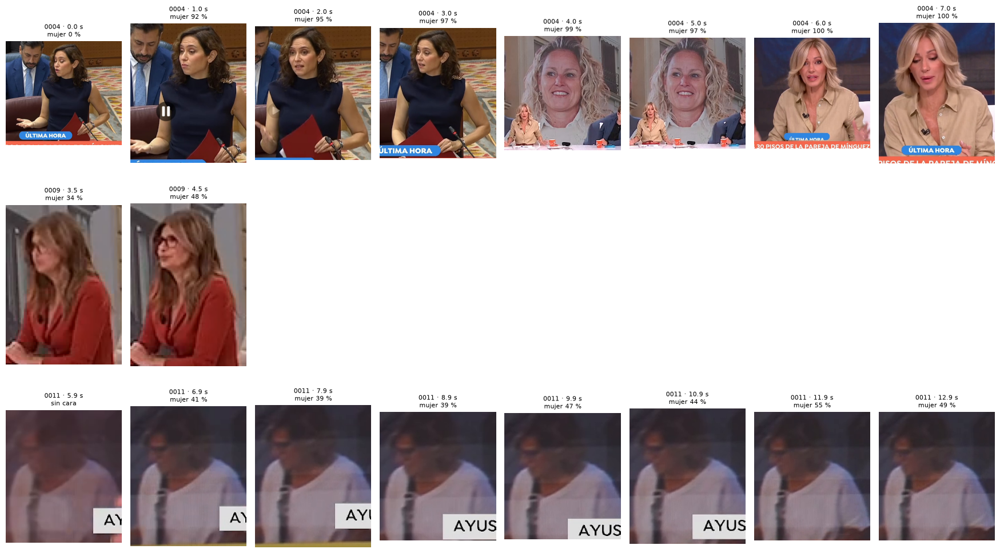

In [43]:
from pathlib import Path
import json
import cv2
import pandas as pd
import matplotlib.pyplot as plt

salida = Path("/workspace/equipo5/PAULA/resultados/video_completo")
fps = json.loads((salida / "progreso_deteccion.json").read_text())["fps"]
gen = pd.read_json(salida / "genero_crops.jsonl", lines=True)

tracks = ["visual_0004", "visual_0009", "visual_0011"]  # cámbialos a voluntad
columnas = 8

fig, ejes = plt.subplots(
    len(tracks), columnas,
    figsize=(2.2 * columnas, 3.4 * len(tracks)), squeeze=False,
)

for fila, tid in enumerate(tracks):
    sub = gen[gen["track_id"] == tid].sort_values("frame_index").head(columnas)
    for col in range(columnas):
        ax = ejes[fila][col]
        ax.axis("off")
        if col >= len(sub):
            continue
        r = sub.iloc[col]
        ax.imshow(cv2.cvtColor(cv2.imread(r["ruta"]), cv2.COLOR_BGR2RGB))
        seg = r["frame_index"] / fps
        if r["estado"] == "cara_detectada":
            ax.set_title(f"{tid[-4:]} · {seg:.1f} s\nmujer {r['prob_mujer']:.0f} %", fontsize=8)
        else:
            ax.set_title(f"{tid[-4:]} · {seg:.1f} s\nsin cara", fontsize=8)

plt.tight_layout()
plt.show()